# 17 — Already a star? Prior All-Stars and the Most Improved award

**In brief**
- **Question:** Do voters pass over players who are already stars?
- **Answer:** Yes. No prior All-Star has won in 26 seasons. Counting it against a candidate improves every test, modestly.
- **Decisions** ([decision log](../docs/DECISIONS.md)): Led to D38.
- **Where it fits:** Feeds the preseason model (11) and the live race (12).
- **Dated:** findings written 9 November 2026; numbers checked against the outputs on 10 November 2026.

**In detail.** Do voters pass over players who have already been recognised as stars? If so, should "already an All-Star" count against a candidate in our Most Improved models?

**Why we're asking.**
- **Our live leaderboard had prior All-Stars near the top.** Alperen Sengun was #2 in early November, Victor Wembanyama and Scottie Barnes were in the top 7, and the betting markets didn't share the view.
- **The scoring turning point (D27) doesn't catch them,** because it only penalises players who scored more than 20 points last season, and several of these scored about 20 or less.

**The input:** `prior_allstar`, 1 if the player was picked for any All-Star game **before** that season, else 0.
- **Only earlier selections count.** Many winners are first picked in the season they win (Paul George, Jimmy Butler, Giannis…), so counting that season's selection would leak the answer.
- **The data:**
  1. Basketball-Reference's All-Star pages (1980 onward) give a broad list of names to check.
  2. NBA.com's own awards record, looked up by player ID, is what counts. This keeps same-name pairs apart, such as Tim Hardaway and Tim Hardaway Jr., or Gary Payton and Gary Payton II.

**How it's judged:** the same tests as before, with and without the input.
- **The 2000-26 history (notebook 15):** three views, each season predicted from earlier seasons only.
- **The preseason model (notebook 11):** leave-one-season-out and strict.
- **The live race (notebook 12):** at four points in the season.

Award votes are used only to score predictions, never to train.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from unicorn.allstars import add_prior_allstar, allstar_selections
from unicorn.labels import MIP_WINNERS
from unicorn.mip import AGE, GAMELOG_DEFENSE, GAMELOG_DELTAS, RELATIVE, SECOND_YEAR, TEAM, ChoiceModel
from unicorn import mip_history as MH
from unicorn.gamelogs import GAMELOG_SEASONS, build_game_table, load_game_logs, mip_candidates
from unicorn.preseason import USED_D29, add_pool_flags, add_star_left, add_turning_point, load_preseason, preseason_frame
from unicorn.plotting import BLUE, FIG_DIR, INK, INK2, MUTED, ORANGE, apply_style
from unicorn.raw import PROJECT_ROOT

warnings.filterwarnings("ignore")
apply_style()
L2, LIVE = 3.0, "2026-27"
games_hist = MH.load_games()                                  # 1999-00 → 2025-26
info = MH.player_info()
votes, winners = MH.voting(games_hist)
live_logs = load_game_logs([LIVE])
players = pd.concat([games_hist[["player_id", "player_name"]], live_logs.rename(columns=str.lower)[["player_id", "player_name"]]]).drop_duplicates("player_id")
SEL_PATH = PROJECT_ROOT / "data" / "processed" / "allstar_selections.parquet"
if SEL_PATH.exists():
    sel = pd.read_parquet(SEL_PATH)
else:
    sel, checked = allstar_selections(players)
    sel.to_parquet(SEL_PATH, index=False)
print(f"{sel['player_id'].nunique()} players with an All-Star selection; {len(sel)} selections")
sel.groupby("season").size().loc["1999-00":].rename("All-Stars").to_frame().T

220 players with an All-Star selection; 900 selections


season,1999-00,2000-01,2001-02,2002-03,2003-04,2004-05,2005-06,2006-07,2007-08,2008-09,...,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25,2025-26
All-Stars,24,28,26,25,24,24,25,28,26,26,...,25,28,27,25,27,27,27,26,23,25


In [2]:
# same-name checks: fathers and sons must not share selections
check = {}
for name in ["Tim Hardaway", "Tim Hardaway Jr.", "Gary Payton", "Gary Payton II", "Glenn Robinson", "Glenn Robinson III", "Larry Nance Jr."]:
    ids = players.loc[players["player_name"] == name, "player_id"]
    check[name] = len(sel[sel["player_id"].isin(ids)])
pd.Series(check, name="All-Star selections").to_frame().T

,Tim Hardaway,Tim Hardaway Jr.,Gary Payton,Gary Payton II,Glenn Robinson,Glenn Robinson III,Larry Nance Jr.
All-Star selections,5,0,9,0,2,0,0


## 17A — How rare is a prior All-Star among candidates, and among those who get votes?

In [3]:
VIEWS = {"end of previous season": (MH.end_of_previous_frame(games_hist, info, winners), MH.PREV_FEATURES, "ppg_last"),
         f"mid-season (day {MH.DAY_MID})": (MH.in_season_frame(games_hist, info, winners, day=MH.DAY_MID), MH.IN_SEASON_FEATURES, "base_ppg"),
         "end of season": (MH.in_season_frame(games_hist, info, winners), MH.IN_SEASON_FEATURES, "base_ppg")}
vote_rank = votes.dropna(subset=["player_id"]).assign(player_id=lambda v: v["player_id"].astype(int)).set_index(["season", "player_id"])["vote_rank"]
rows = []
for name, (f, feats, level) in VIEWS.items():
    f = add_prior_allstar(f, sel)
    f["vote_rank"] = [vote_rank.get((s, int(p)), np.nan) for s, p in zip(f["season"], f["player_id"])]
    VIEWS[name] = (f, feats, level)
    d = MH.with_turn(f, level, 20)
    expected = 0.0                                   # wins the model WITHOUT the input expects prior All-Stars to take
    for s in d["season"].unique():
        p = ChoiceModel(feats + ["over_turn"], L2).fit(d[d["season"] != s]).predict_proba(d[d["season"] == s])
        expected += p[d.loc[d["season"] == s, "prior_allstar"] == 1].sum()
    pa = f[f["prior_allstar"] == 1]
    rows.append({"view": name, "candidates": len(f), "prior All-Stars": len(pa), "share": len(pa) / len(f),
                 "got any votes": int(pa["vote_rank"].notna().sum()), "finished top 5": int((pa["vote_rank"] <= 5).sum()), "won": int(pa["mip"].sum()),
                 "wins expected without the input": expected, "chance of 0 wins if that were right": np.exp(-expected)})
base = pd.DataFrame(rows).set_index("view")
base.style.format({"share": "{:.0%}", "wins expected without the input": "{:.1f}", "chance of 0 wins if that were right": "{:.0%}"})

,candidates,prior All-Stars,share,got any votes,finished top 5,won,wins expected without the input,chance of 0 wins if that were right
view,,,,,,,,
end of previous season,11157,1684,15%,57,5,0,2.5,8%
mid-season (day 85),7331,1299,18%,58,5,0,2.2,11%
end of season,7509,1294,17%,58,5,0,2.2,11%


## 17B — The 2000-26 history: three views, strictly walk-forward (notebook 15's test)

In [4]:
hist_rows, removed = [], {}
for name, (f, feats, level) in VIEWS.items():
    for label, fe in [("without", feats), ("with prior All-Star", feats + ["prior_allstar"])]:
        res, picks = MH.walk_forward(f, fe, level)
        r = res["winner's rank"]
        hist_rows.append({"view": name, "model": label, "winner #1": int((r == 1).sum()), "in top 3": int((r <= 3).sum()), "in top 7": int((r <= 7).sum()),
                          "median rank": r.median(), "× a blind guess": np.exp(np.mean(np.log(res["winner's chance"] * res["candidates"]))),
                          "prior All-Stars in our top 7s": int(picks.merge(f[["season", "player_id", "prior_allstar"]], on=["season", "player_id"])["prior_allstar"].sum())})
        if label == "without":
            pk = picks.merge(f[["season", "player_id", "prior_allstar"]], on=["season", "player_id"])
            removed[name] = pk[pk["prior_allstar"] == 1][["season", "rank", "player_name"]]
hist = pd.DataFrame(hist_rows)
hist.style.format({"× a blind guess": "{:.1f}", "median rank": "{:.0f}"}).hide(axis="index")

view,model,winner #1,in top 3,in top 7,median rank,× a blind guess,prior All-Stars in our top 7s
end of previous season,without,1,2,2,51,2.1,10
end of previous season,with prior All-Star,1,2,2,50,2.3,1
mid-season (day 85),without,4,10,16,4,17.4,14
mid-season (day 85),with prior All-Star,4,10,17,4,19.2,6
end of season,without,7,11,17,2,21.7,9
end of season,with prior All-Star,7,11,17,2,23.1,3


In [5]:
print("prior All-Stars our mid-season model put in its top 7 (without the input):")
removed[f"mid-season (day {MH.DAY_MID})"].style.hide(axis="index")

prior All-Stars our mid-season model put in its top 7 (without the input):


season,rank,player_name
2009-10,5,Carmelo Anthony
2010-11,7,Derrick Rose
2013-14,5,Paul George
2013-14,7,LaMarcus Aldridge
2014-15,6,Anthony Davis
2016-17,4,Isaiah Thomas
2016-17,6,Russell Westbrook
2017-18,6,Giannis Antetokounmpo
2018-19,6,Joel Embiid
2020-21,2,Nikola Jokić


## 17C — The preseason model (notebook 11) and the live race (notebook 12)

In [6]:
regular = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_games.parquet")
ps = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_season.parquet")
pre = load_preseason(regular=regular, refresh_latest=False)
F = add_prior_allstar(add_star_left(add_turning_point(add_pool_flags(preseason_frame(pre, regular, ps), MIP_WINNERS)), pre, regular), sel)
FH, FT = F[F["season"] != LIVE].reset_index(drop=True), F[F["season"] == LIVE].reset_index(drop=True)

from unicorn.mip_eval import scorecard, winner_ranks
KEEP = ["seasons", "in top 7", "in top 20", "median rank", "× a blind guess"]
def pre_scores(feats, scheme):
    c = scorecard(winner_ranks(FH, feats, L2, scheme))
    return {k: c[k] for k in KEEP}

pre_rows = [{"test": t, "model": lab, **pre_scores(fe, t)} for t in ["leave-one-out", "strict"]
            for lab, fe in [("without", USED_D29), ("with prior All-Star", USED_D29 + ["prior_allstar"])]]
pd.DataFrame(pre_rows).style.format({"× a blind guess": "{:.1f}", "median rank": "{:.0f}"}).hide(axis="index")

test,model,seasons,in top 7,in top 20,median rank,× a blind guess
leave-one-out,without,14,7,11,7,7.1
leave-one-out,with prior All-Star,14,8,11,6,8.2
strict,without,9,4,6,15,4.9
strict,with prior All-Star,9,5,6,7,5.6


In [7]:
# live race: same build as notebook 12 (game logs 2010-11 on), turning point 20, leave-one-season-out at four points in the season
import unicorn.live_race as LR
games = LR.live_games()                       # cached game logs; notebook 12 downloads the newest
ps_live = LR.player_table_with_live_season(ps)
EARLY = GAMELOG_DELTAS + GAMELOG_DEFENSE + RELATIVE + TEAM + AGE + SECOND_YEAR + ["base_ppg", "over_turn"]

def race(day):
    return MH.with_turn(LR.race(games, ps_live, day, sel), "base_ppg", 20)

live_rows = []
for day in [14, 30, 60, 85]:
    c = race(day - 1); h = c[c["season"] != LIVE]
    for lab, fe in [("without", EARLY), ("with prior All-Star", EARLY + ["prior_allstar"])]:
        r = winner_ranks(h, fe, L2, "leave-one-out")["rank"].astype(float)
        live_rows.append({"day of season": day, "model": lab, "winner in top 7 (of 15)": int((r <= 7).sum()), "median winner rank": r.median()})
pd.DataFrame(live_rows).pivot(index="day of season", columns="model")

winner in top 7 (of 15)          median winner rank        
model             with prior All-Star without with prior All-Star without
day of season                                                            
14                                  8       8                 5.0     6.0
30                                  8       8                 3.0     3.0
60                                 11      11                 3.0     3.0
85                                 12      11                 3.0     4.0

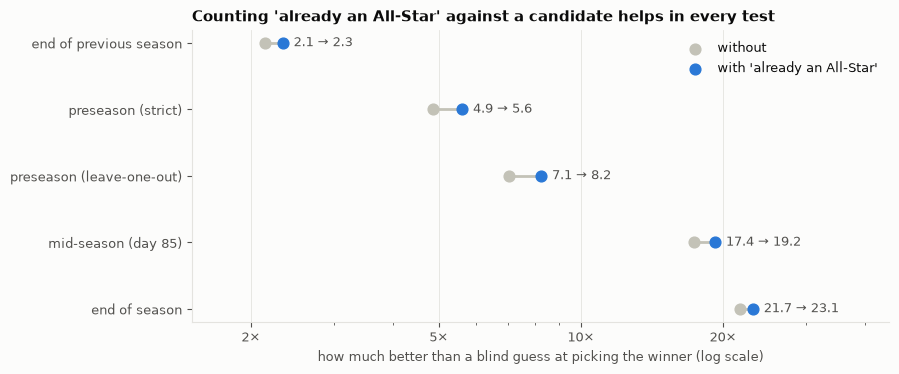

In [9]:
# chart: how much better than a blind guess, without vs with the input, in every test
pts = [(f"{r['view']}", r["× a blind guess"], r["model"]) for _, r in hist.iterrows()]
pts += [(f"preseason ({r['test']})", r["× a blind guess"], r["model"]) for r in pre_rows]
d = pd.DataFrame(pts, columns=["test", "x", "model"]).pivot(index="test", columns="model", values="x")
d = d.loc[["end of previous season", "preseason (strict)", "preseason (leave-one-out)", f"mid-season (day {MH.DAY_MID})", "end of season"]]
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(d))[::-1]
ax.hlines(y, d["without"], d["with prior All-Star"], color=MUTED, linewidth=2)
ax.scatter(d["without"], y, s=60, color=MUTED, zorder=3, label="without")
ax.scatter(d["with prior All-Star"], y, s=60, color=BLUE, zorder=3, label="with 'already an All-Star'")
for yi, (_, r) in zip(y, d.iterrows()):
    ax.annotate(f"{r['without']:.1f} → {r['with prior All-Star']:.1f}", (max(r), yi), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=INK2)
ax.set_xscale("log"); ax.set_yticks(y, d.index); ax.set_xlim(1.5, 45)
ax.set_xticks([2, 5, 10, 20], ["2×", "5×", "10×", "20×"]); ax.xaxis.set_minor_formatter(plt.NullFormatter()); ax.set_xlabel("how much better than a blind guess at picking the winner (log scale)")
ax.legend(frameon=False, loc="upper right"); ax.grid(axis="y", visible=False)
ax.set_title("Counting 'already an All-Star' against a candidate helps in every test", loc="left")
fig.savefig(FIG_DIR / "17_already_a_star.png", dpi=150, bbox_inches="tight")

## 17 findings

**1. Voters do pass over players who are already stars.**
- **About 1 candidate in 6 is a prior All-Star** (15–18%, depending on the point in the season).
- **None of the 26 winners since 2000-01 was one,** and only 5 prior All-Stars finished in the top 5.
- **The model without this input expected them to win about 2 to 2.5 of those 26 awards.** If that were right, zero wins would happen about 1 time in 10. So the pattern is real, but on 26 awards it's suggestive rather than proven.

**2. Counting it against a candidate helps in every test, modestly.**
- **2000-26 history:** better fit at all three points (mid-season 17.4× → 19.2× a blind guess; end of season 21.7× → 23.1×), and one more winner in the mid-season top 7 (17 of 21). How often the winner is #1 or in the top 3 doesn't change.
- **Preseason, strict test:** the winner's median rank halves (15 → 7), with one more winner in the top 7 (5 of 9), and 4.9× → 5.6×.
- **Live race:** at day 85, one more winner in the top 7 (12 of 15) and the median rank improves from 4 to 3. Earlier in the season it makes little difference.
- **What it mostly does is clean up the top 7s.** It removes established stars voters were never going to pick: at mid-season, 14 prior All-Stars in our top 7s become 6. The ones removed include Jokić and Embiid (2020-21), Westbrook (2016-17), Towns (2024-25) and Markkanen (2025-26).

**3. How strong it is:** the live model gives a prior All-Star about **a quarter of the odds** of an otherwise identical player. It's a penalty, not a ban, so a prior All-Star with a huge enough jump can still rank high. That matches no exclusions (D27).

**4. What it changed in 2026-27 when it was added (9 November; the board has moved since, see notebook 12):**
- **Today:** Wembanyama and Scottie Barnes drop out of the top 7, while Anthony Black, Davion Mitchell and Ayo Dosunmu move up and Cooper Flagg reaches #8. Jerome stays clear at #1.
- **Preseason:** Jalen Duren and Tyrese Haliburton (both prior All-Stars) leave the top 7. Brandon Miller (#2), Cooper Flagg, Payton Pritchard and Derrick White come in. That's closer to what the betting markets had in October, though the markets played no part in the model.

**What it doesn't explain:** James Harden's 7th place in 2012-13, or why Flagg is discounted. Neither had a prior All-Star selection, so reputation from other sources is the job of the sentiment trial (TODO, Later).

**Recommendation:** add `prior_allstar` to the preseason model (notebook 11) and the live race (notebook 12), and log it as decision D38. Adding it to the live race rebuilds its daily file from day 1, which is no leak: selections before 2026-27 were known on opening night.